# Project 1: Wealth Inequality in Denmark
This project uses 2024 data to examine wealth inequality across age groups and simulate the effect of an older population.

**Group name:** Programmerings nørderne  
**Members:**

The tasks are in the project PDF. [Course plan: deadline and rules](https://github.com/NumEconCopenhagen/ProgEcon-lectures/blob/main/PLAN_autumn26.md#projects-and-exam) · [Hand-in: Dropbox file request](https://www.dropbox.com/request/6cn75p9izf51x3am6kfe) (one `GroupName_P1_v1.zip` per group)

We measure net wealth in nominal Danish kroner (DKK). Net wealth is the value of assets minus liabilities.

## Download function
`download('FORMUE16', PERCENTIL='*', ...)` asks Statistics Denmark for table FORMUE16. Each keyword is one **variable code** and its value selects the rows you want; `'*'` selects all values. This is the same information as the `variables` list in the Lecture 10 API notebook, written more compactly, and it needs no extra package. The result is a DataFrame with one column per variable and the number in `value`.

To find the codes of another table, open its table information in your browser, for example [FORMUE15](https://api.statbank.dk/v1/tableinfo/FORMUE15?lang=en&format=JSON).

In [1]:
from io import BytesIO
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(table, **selectors):
    """Download a StatBank table as a DataFrame. Each keyword is one variable code; '*' selects all values."""
    url = f'https://api.statbank.dk/v1/data/{table}/CSV'
    params = dict(lang='en', valuePresentation='Code', **selectors)
    response = requests.get(url, params=params, timeout=45)
    response.raise_for_status()
    frame = pd.read_csv(BytesIO(response.content), sep=';', dtype=str, encoding='utf-8-sig')
    frame = frame.rename(columns={frame.columns[-1]: 'value'})
    frame['value'] = pd.to_numeric(frame['value'].str.replace(',', '.', regex=False))
    return frame

settings = dict(PRISENHED='006', ALDER='*', Tid='2024')  # nominal DKK, all age groups, 2024
percentiles = download('FORMUE16', PERCENTIL='*', **settings)
percentiles.head()

,PERCENTIL,PRISENHED,ALDER,TID,value
0,P1,006,1802,2024,-801501
1,P1,006,1829,2024,-437821
2,P1,006,3039,2024,-1097902
3,P1,006,4049,2024,-1128378
4,P1,006,5059,2024,-968947


## 1.1   Download and Read the Tables
The age code `1802` denotes all adults aged 18 or older. The FORMUE15 query uses the 2020 wealth definition (`D20`) and nominal prices (`006`).

In [2]:
counts = download('FORMUE15', FORMUE='*', DEFINITION='D20', **settings)
display(counts.head())

# Separate the published all-adult figures from the eight age groups.
all_adults = '1802'
age_codes = ['1829', '3039', '4049', '5059', '6069', '7079', '8089', '9099']
age_labels = ['18–29', '30–39', '40–49', '50–59', '60–69', '70–79', '80–89', '90+']

percentiles['percentile'] = percentiles['PERCENTIL'].str.replace('P', '', regex=False).astype(int)
national_percentiles = percentiles.loc[percentiles['ALDER'] == all_adults].set_index('percentile')['value']
national_counts = counts.loc[counts['ALDER'] == all_adults]
age_percentiles = percentiles.loc[percentiles['ALDER'].isin(age_codes)]
age_counts = counts.loc[counts['ALDER'].isin(age_codes)]

,FORMUE,DEFINITION,PRISENHED,ALDER,TID,value
0,0000M10,D20,006,1802,2024,35488
1,0000M10,D20,006,1829,2024,2199
2,0000M10,D20,006,3039,2024,9488
3,0000M10,D20,006,4049,2024,8438
4,0000M10,D20,006,5059,2024,7737


## 1.2   Plot the Age Profiles


percentile,P10,P50,P90,Upper gap,Lower gap
Age group,,,,,
18–29,"-14,254","68,806","541,878","473,072","83,060"
30–39,"-118,420","366,935","1,802,110","1,435,175","485,355"
40–49,"4,660","1,024,656","3,718,363","2,693,707","1,019,996"
50–59,"119,753","1,696,187","5,700,964","4,004,777","1,576,434"
60–69,"244,332","2,166,898","6,915,373","4,748,475","1,922,566"
70–79,"174,039","1,733,634","6,437,553","4,703,919","1,559,595"
80–89,"100,122","1,151,164","5,315,410","4,164,246","1,051,042"
90+,"69,644","762,475","4,229,814","3,467,339","692,831"


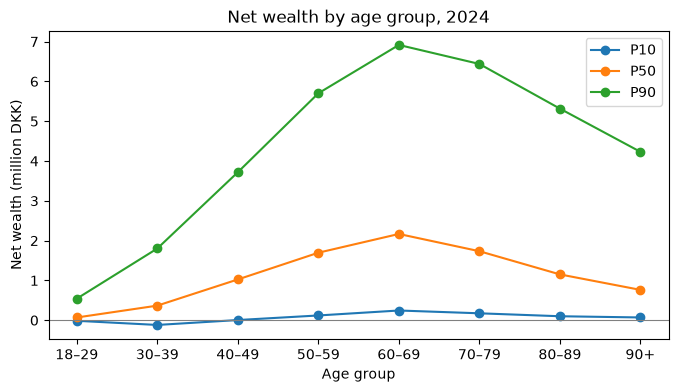

In [3]:
# Pivot to one row per age group and one column per percentile.
profiles = age_percentiles.pivot_table(index='ALDER', columns='percentile', values='value')
profiles = profiles.loc[age_codes, list(range(1, 100))]
gaps = profiles[[10, 50, 90]].rename(columns={10: 'P10', 50: 'P50', 90: 'P90'})
gaps['Upper gap'] = gaps['P90'] - gaps['P50']
gaps['Lower gap'] = gaps['P50'] - gaps['P10']
display(gaps.set_axis(age_labels).rename_axis('Age group').style.format('{:,.0f}'))

fig, ax = plt.subplots(figsize=(8, 4))
for rank in [10, 50, 90]:
    ax.plot(age_labels, profiles[rank] / 1_000_000, marker='o', label=f'P{rank}')
ax.axhline(0, color='gray', linewidth=0.8)
ax.set(xlabel='Age group', ylabel='Net wealth (million DKK)', title='Net wealth by age group, 2024')
ax.legend()
plt.show()

**Interpretation.** Median net wealth rises from DKK 68,806 among adults aged 18–29 to DKK 2,166,898 among those aged 60–69, then declines in the older groups. The 60–69 group also has the widest upper gap, DKK 4,748,475. The upper gap exceeds the lower gap in every age group, indicating that the 90th percentile is farther from the median than the 10th percentile is.

P10 is negative among adults aged 18–29 and 30–39. One possible explanation is that young adults can take on debt early in working life, when they have had fewer years to accumulate financial assets and housing equity. These figures compare different age groups in 2024, so the profile alone cannot show how an individual’s wealth changes with age.

## 1.3   Who Has Negative Net Wealth?


,Adults,Adults with negative wealth,Negative wealth (%)
Age group,,,
18–29,"927,354","112,690",12.15
30–39,"783,901","122,087",15.57
40–49,"708,080","62,699",8.85
50–59,"802,113","41,209",5.14
60–69,"709,729","21,947",3.09
70–79,"581,304","17,437",3.00
80–89,"291,975","8,636",2.96
90+,"47,362",886,1.87


The eight age groups sum to the published total of 4,851,818 adults.


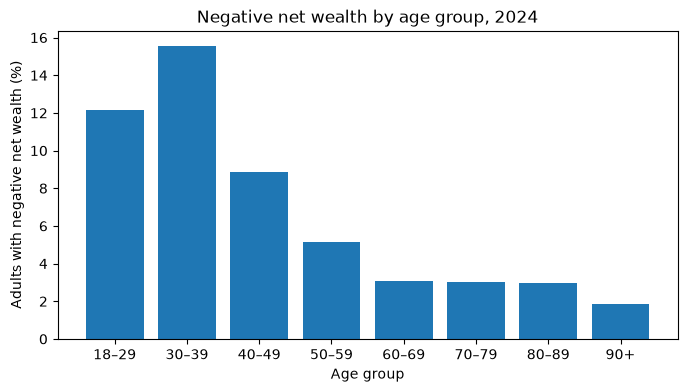

In [4]:
# The three FORMUE15 brackets below zero.
negative_brackets = ['0000M10', 'M100M05', 'M050000']
totals = age_counts.groupby('ALDER')['value'].sum().rename('Adults')
negatives = age_counts.loc[age_counts['FORMUE'].isin(negative_brackets)]
negative_totals = negatives.groupby('ALDER')['value'].sum().rename('Adults with negative wealth')
count_summary = pd.merge(totals, negative_totals, on='ALDER', validate='1:1')
count_summary['Negative wealth (%)'] = 100 * count_summary['Adults with negative wealth'] / count_summary['Adults']
age_summary = pd.merge(gaps, count_summary, on='ALDER', validate='1:1').loc[age_codes]
display(age_summary[count_summary.columns].set_axis(age_labels).rename_axis('Age group').style.format(
    {'Adults': '{:,.0f}', 'Adults with negative wealth': '{:,.0f}', 'Negative wealth (%)': '{:.2f}'}
))

national_total = national_counts['value'].sum()
assert age_summary['Adults'].sum() == national_total
print(f'The eight age groups sum to the published total of {national_total:,.0f} adults.')

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(age_labels, age_summary['Negative wealth (%)'])
ax.set(xlabel='Age group', ylabel='Adults with negative net wealth (%)',
       title='Negative net wealth by age group, 2024')
plt.show()

**Interpretation.** Negative net wealth is most common among adults aged 30–39 (15.57%), even though their median wealth is higher than that of adults aged 18–29, whose negative-wealth share is 12.15%. The median and the share below zero capture different parts of the distribution. Among adults aged 90 or older, median wealth is below its peak at ages 60–69, yet the negative-wealth rate is the lowest of all eight groups (1.87%).

## 2.1   Give Everybody Their Age-Group Median


In [5]:
from dataproject import simulate_wealth

age_shares = (age_summary['Adults'] / national_total).to_numpy()
assert np.isclose(age_shares.sum(), 1)
print(f'The published age shares sum to {age_shares.sum():.2f}.')

wealth_percentiles = profiles.to_numpy()
age, wealth_median, wealth_varied = simulate_wealth(age_shares, wealth_percentiles)
simulated_shares = np.array([np.mean(age == j) for j in range(len(age_codes))])

shares = pd.DataFrame({
    'Published share (%)': 100 * age_shares,
    'Simulated share (%)': 100 * simulated_shares,
    'Difference (percentage points)': 100 * (simulated_shares - age_shares)
}, index=age_labels).rename_axis('Age group')
display(shares.style.format('{:.2f}'))

The published age shares sum to 1.00.


,Published share (%),Simulated share (%),Difference (percentage points)
Age group,,,
18–29,19.11,19.42,0.31
30–39,16.16,16.24,0.08
40–49,14.59,14.38,-0.21
50–59,16.53,17.03,0.50
60–69,14.63,14.26,-0.37
70–79,11.98,11.79,-0.19
80–89,6.02,5.78,-0.24
90+,0.98,1.10,0.12


**Interpretation.** The simulated age shares are close to the published shares. The largest difference is about 0.50 percentage points for ages 50–59. The published shares determine the probability of each age group, while the realised shares vary because the simulation uses a finite random sample of 10,000 adults.

## 2.2   Allow Wealth to Vary Within Each Age Group


In [6]:
# Show how the two wealth assignments differ for the same simulated adults.
examples = pd.DataFrame({
    'Age group': np.array(age_labels)[age[:5]],
    'Age-group median (DKK)': wealth_median[:5],
    'Wealth at drawn percentile (DKK)': wealth_varied[:5]
})
display(examples.style.format({
    'Age-group median (DKK)': '{:,.0f}',
    'Wealth at drawn percentile (DKK)': '{:,.0f}'
}))

,Age group,Age-group median (DKK),Wealth at drawn percentile (DKK)
0,60–69,"2,166,898","16,902"
1,40–49,"1,024,656","1,907,146"
2,70–79,"1,733,634","510,312"
3,60–69,"2,166,898","3,620,483"
4,18–29,"68,806","89,864"


## 2.3   Compare Both Economies with Denmark


In [7]:
def wealth_statistics(wealth):
    # Return the three percentiles, the gap and the share below zero.
    p10, p50, p90 = np.percentile(wealth, [10, 50, 90])
    return [p10, p50, p90, p90 - p10, 100 * np.mean(wealth < 0)]

national_negative = national_counts.loc[national_counts['FORMUE'].isin(negative_brackets), 'value'].sum()
p10, p50, p90 = national_percentiles.loc[[10, 50, 90]]
observed = [p10, p50, p90, p90 - p10, 100 * national_negative / national_total]

stat_labels = ['P10 (DKK)', 'P50 (DKK)', 'P90 (DKK)', 'P90–P10 (DKK)', 'Negative wealth (%)']
stat_formats = {label: '{:,.0f}' for label in stat_labels[:4]}
stat_formats['Negative wealth (%)'] = '{:.2f}'
comparison = pd.DataFrame(
    [observed, wealth_statistics(wealth_median), wealth_statistics(wealth_varied)],
    index=['Observed Denmark', 'Age-group medians only', 'Variation within age groups'],
    columns=stat_labels
)
display(comparison.style.format(stat_formats))

gap_fraction = comparison.loc['Age-group medians only', 'P90–P10 (DKK)'] / (p90 - p10)
print(f'The median-only economy reproduces {gap_fraction:.1%} of the observed gap.')

,P10 (DKK),P50 (DKK),P90 (DKK),P90–P10 (DKK),Negative wealth (%)
Observed Denmark,"4,875","813,665","4,501,923","4,497,048",7.99
Age-group medians only,"68,806","1,024,656","2,166,898","2,098,092",0.00
Variation within age groups,"8,639","813,339","4,377,805","4,369,166",7.54


The median-only economy reproduces 46.7% of the observed gap.


**Interpretation.** Giving every adult their age-group median reproduces 46.7% of the observed P90–P10 gap. This measures the spread generated by differences in typical wealth across age groups in this simulation. All eight group medians are positive, so this economy has no adults with negative wealth.

Allowing wealth to vary within age groups brings the simulated distribution much closer to the observed distribution. The median is DKK 813,339, compared with DKK 813,665 in Denmark. The simulated gap is about 2.8% smaller than the observed gap, and the negative-wealth share is 7.54%, compared with 7.99%. A close match is expected because the simulation combines the observed age shares and age-specific wealth thresholds. Differences remain because each within-age distribution is represented by 99 discrete thresholds, and a finite random sample adds sampling variation.

## 2.4   An Older Denmark


In [8]:
older_shares = age_shares.copy()
older_shares[age_codes.index('1829')] -= 0.05
older_shares[age_codes.index('7079')] += 0.05
assert np.isclose(older_shares.sum(), 1)

_, _, wealth_older = simulate_wealth(older_shares, wealth_percentiles, seed=42)
ageing_comparison = pd.DataFrame(
    [wealth_statistics(wealth_varied), wealth_statistics(wealth_older)],
    index=['2024 age shares', 'Older population'],
    columns=stat_labels
)
display(ageing_comparison.style.format(stat_formats))

,P10 (DKK),P50 (DKK),P90 (DKK),P90–P10 (DKK),Negative wealth (%)
2024 age shares,"8,639","813,339","4,377,805","4,369,166",7.54
Older population,"12,894","944,718","4,657,071","4,644,177",7.10


**Interpretation.** Shifting five percentage points of the adult population from ages 18–29 to ages 70–79 raises the simulated median from DKK 813,339 to DKK 944,718. Median wealth at ages 70–79 is DKK 1,733,634, compared with DKK 68,806 at ages 18–29. The P90–P10 gap widens from DKK 4,369,166 to DKK 4,644,177 because P90 rises by more than P10. This is consistent with the particularly large difference between the age groups at P90, where their thresholds are about DKK 6.44 million and DKK 0.54 million, respectively. The simulated negative-wealth share falls from 7.54% to 7.10%, consistent with the lower observed rate at ages 70–79 (3.00%) than at ages 18–29 (12.15%).

Using the same seed gives both simulations the same uniform age draws and percentile ranks. This reduces random variation in the comparison and ties the changes to the new age shares. In an actual ageing population, a change in house prices could alter housing equity and therefore the wealth distribution within age groups. The simulation holds those distributions fixed and isolates the effect of changing the population weights.

Data: [StatBank FORMUE16](https://www.statbank.dk/FORMUE16) and [StatBank FORMUE15](https://www.statbank.dk/FORMUE15).